In [1]:
from openfermion import FermionOperator, QubitOperator, jordan_wigner, lambda_norm, hermitian_conjugated
from openfermion import hermitian_conjugated, normal_ordered, get_sparse_operator
import matplotlib.pyplot as plt
from sympy.physics.quantum.matrixutils import sparse


In [2]:
# a b a b a b
state = FermionOperator('0^ 1^')

Time evolution according to a simple Hamiltonian

In [3]:
H = FermionOperator('0 1^')
# Hh = H + hermitian_conjugated(H)

Hh = FermionOperator('1 2^') + FermionOperator('2 1^')
#Hh = 0.8 * FermionOperator('0^ 0') - 0.2 * FermionOperator('1^ 1')  # must be Hermitian
# must be Hermitian

In [4]:
def is_hermitian(op):
    hermitian_part = normal_ordered(op - hermitian_conjugated(op))
    return len(hermitian_part.terms) == 0

print('is hermitian?')
print('H : ', is_hermitian(H))
print('Hh: ', is_hermitian(Hh))

is hermitian?
H :  False
Hh:  True


In [5]:
t_qubit = jordan_wigner(H)
print(t_qubit)


(-0.25+0j) [X0 X1] +
0.25j [X0 Y1] +
-0.25j [Y0 X1] +
(-0.25+0j) [Y0 Y1]


In [189]:
ha_qubit = jordan_wigner(Hh)
print(ha_qubit)


(-0.5+0j) [X1 X2] +
(-0.5+0j) [Y1 Y2]


In [25]:
from scipy.sparse.linalg import expm, expm_multiply

vec = get_sparse_operator(state, n_qubits=3)
for op in ha_qubit.get_operators():
    sparse_op = get_sparse_operator(op, n_qubits=3)
    vec = expm_multiply(sparse_op, vec)

print(vec)

<Compressed Sparse Column sparse matrix of dtype 'complex128'
	with 4 stored elements and shape (8, 8)>
  Coords	Values
  (5, 0)	(-1.1752011936438016+0j)
  (6, 0)	(1.543080634815244+0j)
  (4, 1)	(9.746099720404205e-17+0j)
  (7, 1)	(1.0000000000000002+0j)


In [26]:
vec_ini = get_sparse_operator(state, n_qubits=3)
print((vec_ini.T.conj() @ vec)[0, 0])


(1.543080634815244+0j)


In [27]:
state_ref1 = FermionOperator('0^ 1^')
state_ref2 = FermionOperator('0^ 2^')

sparse_ref1 = get_sparse_operator(state_ref1, n_qubits=3)
sparse_ref2 = get_sparse_operator(state_ref2, n_qubits=3)


In [28]:
from scipy.sparse.linalg import expm, expm_multiply

def time_evolution(t):
    vec = get_sparse_operator(state, n_qubits=3)
    sparse_op = -1j*t * get_sparse_operator(ha_qubit, n_qubits=3)
    vec = expm_multiply(sparse_op, vec)
    return vec


In [29]:
from scipy.sparse.linalg import expm, expm_multiply

def time_evolution_trotter(t):
    vec = get_sparse_operator(state, n_qubits=3)
    for op in ha_qubit.get_operators():
        sparse_op =-1j*t * get_sparse_operator(op, n_qubits=3)
        vec = expm_multiply(sparse_op, vec)
    return vec

(-1.0, 1.0)

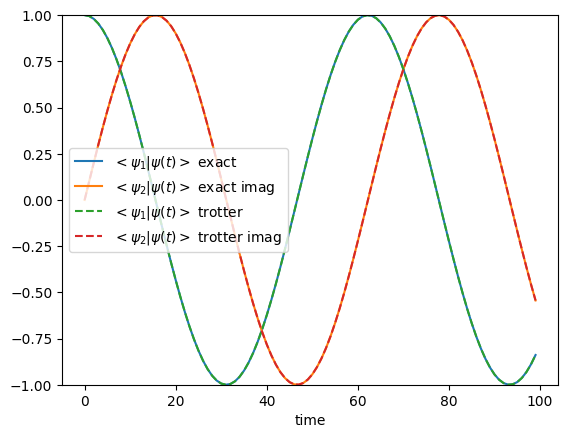

In [215]:
exact_1 = []
exact_2 = []
trotter_1 = []
trotter_2 = []
import numpy as np
for t in np.linspace(0, 10, 100):

    sparse_state = time_evolution(t)

    exact_1.append((sparse_ref1.T.conj() @ sparse_state)[0, 0].real)
    exact_2.append((sparse_ref2.T.conj() @ sparse_state)[0, 0].imag)

    sparse_state = time_evolution_trotter(t)

    trotter_1.append((sparse_ref1.T.conj() @ sparse_state)[0, 0].real)
    trotter_2.append((sparse_ref2.T.conj() @ sparse_state)[0, 0].imag)

plt.plot(exact_1, label='$<\psi_1 | \psi(t)>$ exact')
plt.plot(exact_2, label='$<\psi_2 | \psi(t)>$ exact imag')

plt.plot(trotter_1, '--', label='$<\psi_1 | \psi(t)>$ trotter')
plt.plot(trotter_2, '--', label='$<\psi_2 | \psi(t)>$ trotter imag')
plt.legend()
plt.xlabel('time')
plt.ylim(-1, 1)

(-1.0, 1.0)

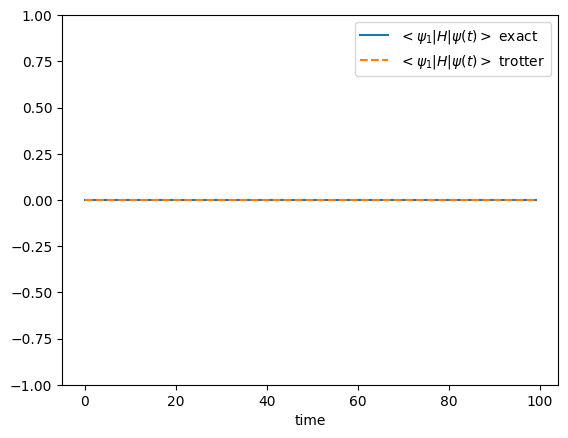

In [145]:
Hh_sparse = get_sparse_operator(ha_qubit, n_qubits=3)

exact = []
trotter = []
import numpy as np
for t in np.linspace(0, 10, 100):

    sparse_state = time_evolution(t)

    exact.append((sparse_state.T.conj() @ Hh_sparse @ sparse_state)[0, 0].real)

    sparse_state = time_evolution_trotter(t)

    trotter.append((sparse_state.T.conj() @ Hh_sparse @  sparse_state)[0, 0].real)

plt.plot(exact, label='$<\psi_1 | H | \psi(t)>$ exact')
plt.plot(trotter, '--', label='$<\psi_1 | H | \psi(t)>$ trotter')
plt.legend()
plt.xlabel('time')
plt.ylim(-1, 1)

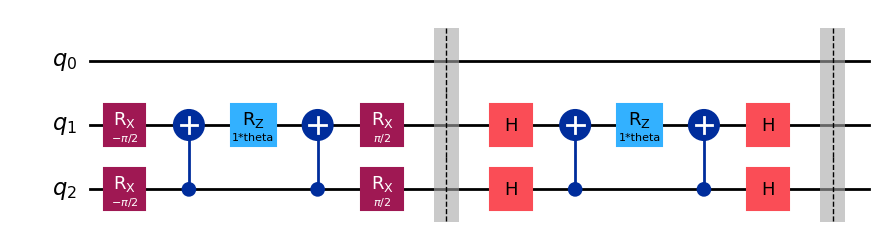

In [238]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector, Parameter

te_qubit = -1j * ha_qubit

# Define the variational parameter
theta = Parameter("theta")

# Build the ansatz
qc = QuantumCircuit(3)

i_op = 0
for op, coef in te_qubit.terms.items():

    for qubit, pauli in op:
        if pauli == 'X':
            qc.h(qubit)
        elif pauli == 'Y':
            qc.rx(np.pi / 2, [qubit])

    for qubit, pauli in op[1:]:
        qc.cx(qubit, op[0][0])

    if len(op) > 0:
        qc.rz(2*theta * coef.imag, op[0][0])

    for qubit, pauli in reversed(op[1:]):
        qc.cx(qubit, op[0][0])

    for qubit, pauli in op:
        if pauli == 'X':
            qc.h(qubit)
        elif pauli == 'Y':
            qc.rx(np.pi / 2, [qubit])

    qc.barrier()

qc.draw('mpl')

In [239]:
from qiskit.primitives import StatevectorSampler

def cost_function(params):
    energy = 0.0
    for op, coeff in ha_qubit.terms.items():

        # setup circuit
        qc_prep = QuantumCircuit(3)

        # reference
        qc_prep.x(0)
        qc_prep.x(1)
        qc_prep = qc_prep.compose(qc.assign_parameters(params))

        qc_meas = qc_prep.copy()

        # set measurement basis
        for qi, pauli in op:
            if pauli == "X":
                qc_meas.h(qi)
            if pauli == "Y":
                qc_meas.rx(np.pi / 2, qi)
                #qc_meas.sdg(qi)
                #qc_meas.h(qi)

        # add mesure
        qc_meas.measure_all()

        # Sample
        sampler = StatevectorSampler()

        result = sampler.run([qc_meas], shots=1000).result()
        counts = result[0].data.meas.get_counts()

        shots = sum(counts.values())

        # compute expected value
        for bitstring, count in counts.items():

            parity = 1
            for qi, pauli in op:
                if bitstring[::-1][qi] == "1":
                    parity *= -1

            energy += parity * count / shots * coeff

    return energy.real

cost_function([0.0])

0.024000000000000007

(-1.0, 1.0)

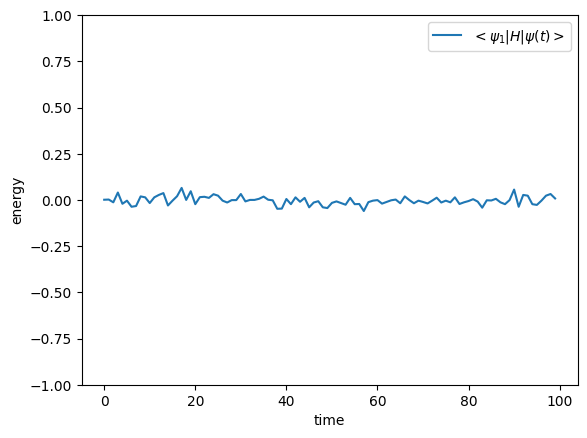

In [240]:
trotter = []
import numpy as np
for t in np.linspace(0, 10, 100):
    energy = cost_function([t])
    trotter.append(energy)

plt.plot(trotter, label='$<\psi_1 | H | \psi(t)>$')
plt.legend()
plt.xlabel('time')
plt.ylabel('energy')
plt.ylim(-1, 1)

- Try with a different hamiltonian (whose energy is not zero for the |11> state
- change the initial state an observe what happens
- Why the energy is constant?
- change the reference states to analyze how is the initial state evolving


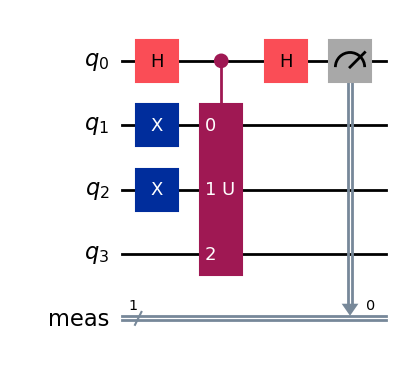

In [246]:
from qiskit import QuantumCircuit, ClassicalRegister, QuantumRegister
from qiskit.primitives import StatevectorSampler

c_reg = ClassicalRegister(1, "meas")
q = QuantumRegister(4, r'q')

def remove_barriers(qc):
    qc = qc.copy()
    qc.data = [
        instruction
        for instruction in qc.data
        if instruction.operation.name != "barrier"
    ]
    return qc

def evolution_gate(params):

    # state evolution
    evol = remove_barriers(qc)
    evol = evol.assign_parameters(params)

    # Conditional transformation |101> -> |110>

    evol.x(1)
    evol.x(2)

    return evol.to_gate(label="U")


# Build the ansatz
def get_hadamard_test_circuit(params, imaginary_part=False):

    qc_test = QuantumCircuit(q, c_reg)

    # reference
    qc_test.x(1)
    qc_test.x(2)

    qc_test.h(0)


    if imaginary_part:
        qc_test.s(0) # for imaginary part

    U_gate = evolution_gate(params)

    U_controlled_gate = U_gate.control(1)

    qc_test.append(U_controlled_gate, [0, 1, 2, 3])
    qc_test.h(0)

    qc_test.measure(q[0], c_reg)

    return qc_test

get_hadamard_test_circuit([0.1]).draw('mpl')



-0.00049
0.502264
0.8688
0.999972
0.860748
0.488968
-0.016984
-0.51719
-0.877532
-0.999696
-0.851232
-0.473016
0.03368
0.530288
0.884536
0.999192
0.843928
0.460038
-0.0494
-0.543992


(-1.0, 1.0)

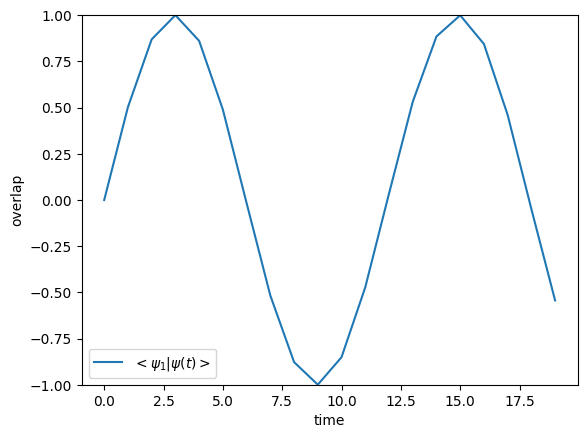

In [247]:
def cost_function_overlap(params):

    sampler = StatevectorSampler()

    n_shots = 1000000

    # real part
    qc_test = get_hadamard_test_circuit(params, imaginary_part=True)
    result = sampler.run([qc_test], shots=n_shots).result()
    counts = result[0].data.meas.get_counts()
    overlap_real = (counts.get('0', 0) - counts.get('1', 0)) / n_shots

    # imaginary part
    #qc_test = get_hadamard_test_circuit(params, imaginary=True)
    #result = sampler.run([qc_test], shots=n_shots).result()
    #counts = result[0].data.meas.get_counts()
    #overlap_imag = (counts.get('0', 0) - counts.get('1', 0)) / n_shots
    # overlap = overlap_real +  ij* overlap_imag

    print(overlap_real)
    return overlap_real

overlaps = []
import numpy as np
for t in np.linspace(0, 10, 20):
    overlaps.append(cost_function_overlap([t]))

plt.plot(overlaps, label='$<\psi_1 | \psi(t)>$')
plt.legend()
plt.xlabel('time')
plt.ylabel('overlap')
plt.ylim(-1, 1)

- change the circuit to compute the overlap <110 | U | 101>
- learn phase kickback